# 03 – Cart abandonment and buyer types

How many users do we lose at the cart (Q1), and how fast do buyers decide (Q3)?
The data comes from the dbt table `otto.mart_sessions` (one row per user).

In [8]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine
from statsmodels.stats.proportion import proportion_confint

sns.set_theme(style="white", font_scale=1.1)

DATA_FILE = Path("../data/processed/mart_sessions.parquet")
FIG_DIR = Path("../docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# one colour = one meaning, in every chart (and later in Tableau)
COLORS = {
    "users": "#c9ced6",           # all users / visits (grey)
    "cart": "#e9c46a",            # added to cart (yellow)
    "ordered": "#2a9d8f",         # ordered (green)
    "abandoner": "#e4572e",       # cart but no order = lost (orange)
    "quick_buyer": "#2a9d8f",     # ordered within 1 hour (green)
    "same_day_buyer": "#8ab17d",  # ordered within 1 day (light green)
    "slow_buyer": "#264653",      # ordered after 1+ day (dark blue)
    "highlight": "#e4572e",       # lines and notes (orange)
}
LABELS = {
    "abandoner": "Never ordered",
    "quick_buyer": "Within 1 hour",
    "same_day_buyer": "1–24 hours",
    "slow_buyer": "After 1+ day",
}

## Load the data

The table is downloaded once from PostgreSQL and saved locally, so the next runs are fast.
The connection details are in the `.env` file in the project folder (not on GitHub).

In [9]:
if DATA_FILE.exists():
    sessions = pd.read_parquet(DATA_FILE)
else:
    load_dotenv("../.env", override=True)
    engine = create_engine(
        f"postgresql://{os.getenv('POSTGRES_USER')}:{os.getenv('POSTGRES_PASS')}"
        f"@{os.getenv('POSTGRES_HOST')}:{os.getenv('POSTGRES_PORT')}/{os.getenv('POSTGRES_DB')}"
    )
    query = """
        SELECT session_id, has_cart, has_order, buyer_type,
               hours_cart_to_order, starts_with_cart_or_order, active_days, n_clicks
        FROM otto.mart_sessions
    """
    sessions = pd.read_sql(query, engine)
    sessions.to_parquet(DATA_FILE, index=False)

print(sessions.shape)
sessions.head()

(1000000, 8)


,session_id,has_cart,has_order,buyer_type,hours_cart_to_order,starts_with_cart_or_order,active_days,n_clicks
0,1545849,True,True,quick_buyer,0.21,False,5,14
1,1545872,False,False,browser,NaN,False,7,15
2,1545875,True,False,abandoner,NaN,False,10,154
3,1545900,False,False,browser,NaN,False,1,5
4,1545923,True,False,abandoner,NaN,False,8,74


## 1. The funnel

In [10]:
n_users = len(sessions)
n_cart = sessions["has_cart"].sum()
n_order = sessions["has_order"].sum()

funnel = pd.DataFrame({
    "step": ["Visited", "Added to cart", "Ordered"],
    "users": [n_users, n_cart, n_order],
})
funnel["share"] = funnel["users"] / n_users * 100
funnel

,step,users,share
0,Visited,1000000,100.0000
1,Added to cart,294974,29.4974
2,Ordered,126166,12.6166


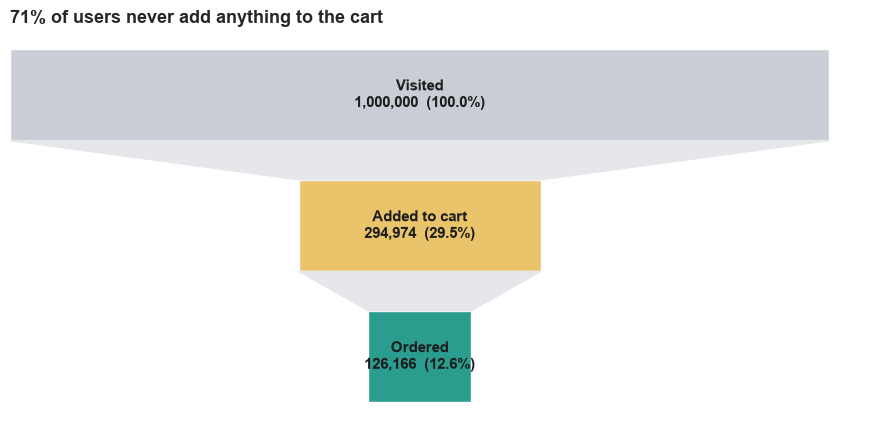

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [COLORS["users"], COLORS["cart"], COLORS["ordered"]]
text_colors = ["#1d1d1d", "#1d1d1d", "#1d1d1d"]
y_pos = [2, 1, 0]  # first step at the top

# centre each bar, so the chart looks like a funnel
funnel["left"] = (n_users - funnel["users"]) / 2

for i, row in funnel.iterrows():
    ax.barh(y_pos[i], row["users"], left=row["left"], height=0.7, color=colors[i])
    ax.text(n_users / 2, y_pos[i], f"{row['step']}\n{row['users']:,.0f}  ({row['share']:.1f}%)",
            ha="center", va="center", fontsize=11, fontweight="bold", color=text_colors[i])

# light grey shapes between the bars
for i in range(len(funnel) - 1):
    top, bottom = funnel.loc[i], funnel.loc[i + 1]
    ax.fill(
        [top["left"], top["left"] + top["users"], bottom["left"] + bottom["users"], bottom["left"]],
        [y_pos[i] - 0.35, y_pos[i] - 0.35, y_pos[i + 1] + 0.35, y_pos[i + 1] + 0.35],
        color="#e5e7eb",
    )

no_cart_share = 100 - funnel.loc[1, "share"]
ax.set_title(f"{no_cart_share:.0f}% of users never add anything to the cart", loc="left", fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_funnel.png", dpi=200)
plt.show()


## 2. Cart abandonment rate (Q1)

Only users with a cart add. `late_cart` (cart on Aug 27–28) and `other` (no cart in the data period) are left out.

In [12]:
cart_users = sessions[sessions["buyer_type"].isin(["abandoner", "quick_buyer", "same_day_buyer", "slow_buyer"])]

n_cart_users = len(cart_users)
n_abandoned = (cart_users["buyer_type"] == "abandoner").sum()
abandon_rate = n_abandoned / n_cart_users

# 95% confidence interval for the abandonment rate
low, high = proportion_confint(n_abandoned, n_cart_users, alpha=0.05, method="wilson")

print(f"Users with a cart: {n_cart_users:,}")
print(f"Never ordered:     {n_abandoned:,}")
print(f"Abandonment rate:  {abandon_rate:.1%}  (95% CI {low:.1%} to {high:.1%})")

Users with a cart: 280,924
Never ordered:     159,946
Abandonment rate:  56.9%  (95% CI 56.8% to 57.1%)


The confidence interval is very narrow because the sample is large: the real rate is almost surely in this range.

In [13]:
type_order = ["abandoner", "quick_buyer", "same_day_buyer", "slow_buyer"]

type_share = cart_users["buyer_type"].value_counts(normalize=True) * 100
type_share = type_share.reindex(type_order).reset_index()
type_share.columns = ["buyer_type", "share"]
type_share["label"] = type_share["buyer_type"].map(LABELS)
type_share

,buyer_type,share,label
0,abandoner,56.935684,Never ordered
1,quick_buyer,29.090786,Within 1 hour
2,same_day_buyer,5.789110,1–24 hours
3,slow_buyer,8.184420,After 1+ day


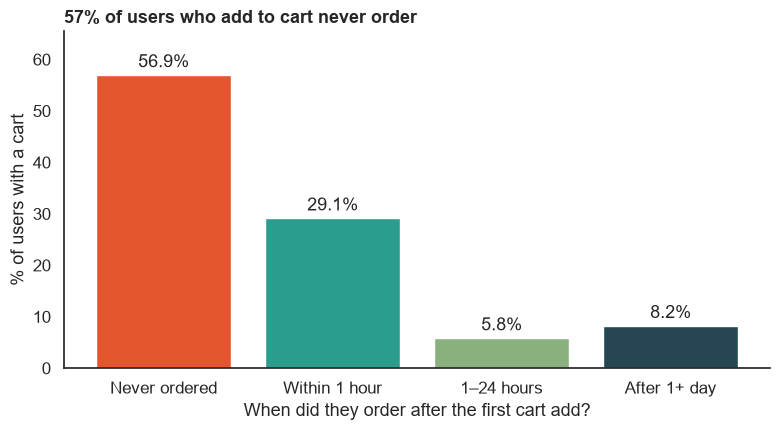

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(type_share["label"], type_share["share"], color=[COLORS[t] for t in type_share["buyer_type"]])
ax.bar_label(bars, fmt="%.1f%%", padding=3)

ax.set_title(f"{abandon_rate:.0%} of users who add to cart never order", loc="left", fontweight="bold")
ax.set_ylabel("% of users with a cart")
ax.set_xlabel("When did they order after the first cart add?")
ax.set_ylim(0, type_share["share"].max() * 1.15)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_buyer_types.png", dpi=200)
plt.show()

## 3. Time from cart to order (Q3)

Only buyers. Users whose session starts with a cart or order are left out, because their real start is before August 1st.

In [15]:
buyers = sessions[sessions["buyer_type"].isin(["quick_buyer", "same_day_buyer", "slow_buyer"])]
buyers = buyers[~buyers["starts_with_cart_or_order"]]

hours = buyers["hours_cart_to_order"]
print(f"Buyers:                {len(buyers):,}")
print(f"Median time to order:  {hours.median() * 60:.0f} minutes")
print(f"Within 1 hour:         {(hours < 1).mean():.1%}")
print(f"Within 24 hours:       {(hours < 24).mean():.1%}")
print(f"After more than 1 day: {(hours >= 24).mean():.1%}")

Buyers:                119,398
Median time to order:  14 minutes
Within 1 hour:         67.6%
Within 24 hours:       81.0%
After more than 1 day: 19.0%


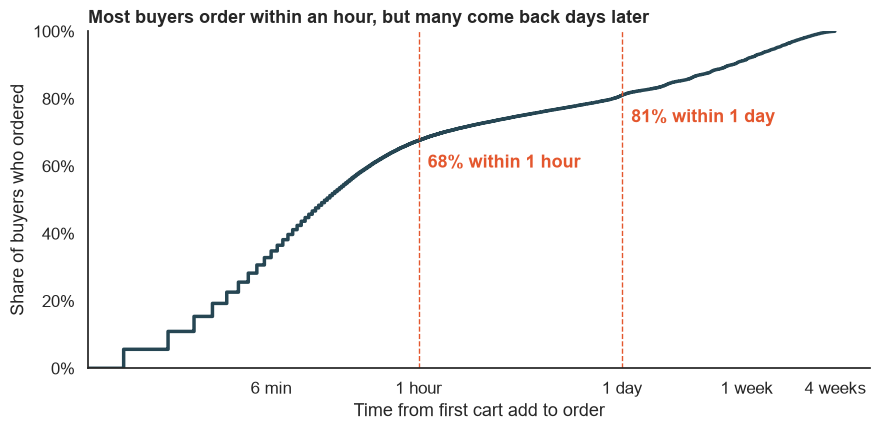

In [16]:
# the log scale can't show 0, so very fast orders are shown as 0.01 hours (36 seconds)
plot_hours = hours.clip(lower=0.01)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.ecdfplot(x=plot_hours, ax=ax, color=COLORS["slow_buyer"], linewidth=2.5)
ax.set_xscale("log")

for limit, text in [(1, "1 hour"), (24, "1 day")]:
    share = (hours < limit).mean()
    ax.axvline(limit, color=COLORS["highlight"], linestyle="--", linewidth=1)
    ax.text(limit * 1.15, share - 0.08, f"{share:.0%} within {text}", color=COLORS["highlight"], fontweight="bold")

ax.set_xticks([0.1, 1, 24, 168, 672])
ax.set_xticklabels(["6 min", "1 hour", "1 day", "1 week", "4 weeks"])
ax.yaxis.set_major_formatter(lambda y, pos: f"{y:.0%}")
ax.set_xlabel("Time from first cart add to order")
ax.set_ylabel("Share of buyers who ordered")
ax.set_title("Most buyers order within an hour, but many come back days later", loc="left", fontweight="bold")
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "03_time_to_order.png", dpi=200)
plt.show()

## 4. How many buyers could we win back? (Q1)

If a cart reminder brings back 5%, 10% or 20% of the users who never ordered.
The last column scales the sample (1M users) up to the full data (12.9M users).

In [17]:
current_buyers = sessions["has_order"].sum()
FULL_DATA_FACTOR = 12_899_779 / n_users

scenarios = pd.DataFrame({"recovered_%": [5, 10, 20]})
scenarios["extra_buyers"] = (n_abandoned * scenarios["recovered_%"] / 100).round().astype(int)
scenarios["more_buyers_%"] = scenarios["extra_buyers"] / current_buyers * 100
scenarios["extra_buyers_full_data"] = (scenarios["extra_buyers"] * FULL_DATA_FACTOR).round().astype(int)
scenarios

,recovered_%,extra_buyers,more_buyers_%,extra_buyers_full_data
0,5,7997,6.338475,103160
1,10,15995,12.677742,206332
2,20,31989,25.354691,412651


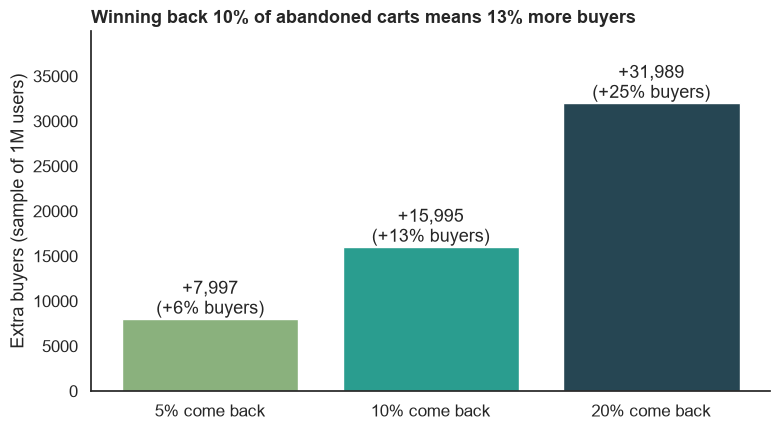

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [f"{p}% come back" for p in scenarios["recovered_%"]]
bars = ax.bar(labels, scenarios["extra_buyers"], color=["#8ab17d", "#2a9d8f", "#264653"])

for bar, extra, more in zip(bars, scenarios["extra_buyers"], scenarios["more_buyers_%"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"+{extra:,}\n(+{more:.0f}% buyers)",
            ha="center", va="bottom")

ten = scenarios.loc[scenarios["recovered_%"] == 10, "more_buyers_%"].iloc[0]
ax.set_title(f"Winning back 10% of abandoned carts means {ten:.0f}% more buyers", loc="left", fontweight="bold")
ax.set_ylabel("Extra buyers (sample of 1M users)")
ax.set_ylim(0, scenarios["extra_buyers"].max() * 1.25)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "04_recovery_scenarios.png", dpi=200)
plt.show()